In [9]:
import numpy as np
from scipy.optimize import fsolve

# Parametri
mr = 2.0    # ritenis [kg]
mk = 80.0   # korpuss [kg]
Ir = 0.32   # riteņa inerce [kg*m^2]
rr = 0.4    # riteņa rādiuss [m]
Lk = 1.0    # līdz korpusa masas centram [m]
g  = 9.81

mT = mr + mk + Ir / rr**2   # kopējā masa

u = 50.0    # virzes spēks [N]


# Nelineārais: f(θ) = u·(rr + mk·Lk·cosθ/mT) − mk·g·Lk·sinθ
def f(theta):
    return u * (rr + mk * Lk * np.cos(np.deg2rad(theta)) / mT) - mk * g * Lk * np.sin(np.deg2rad(theta))


# Atrod θ, kur f(θ) = 0
theta1 = fsolve(f, 0)[0]     # sākums 0
theta2 = fsolve(f, 180)[0]    # sākums 180

# Linearizētais: θ = (u/mT + u·rr/(mk·Lk)) / g
theta_lin = (u / mT + u * rr / (mk * Lk)) / g
theta_lin = np.rad2deg(theta_lin)

print("Nelineārais, sākums 0: ", theta1)
print("Nelineārais, sākums -3:", theta2)
print("Linearizētais:         ", theta_lin)

Nelineārais, sākums 0:  4.929873690885963
Nelineārais, sākums -3: 182.01464598597755
Linearizētais:          4.936653979696185


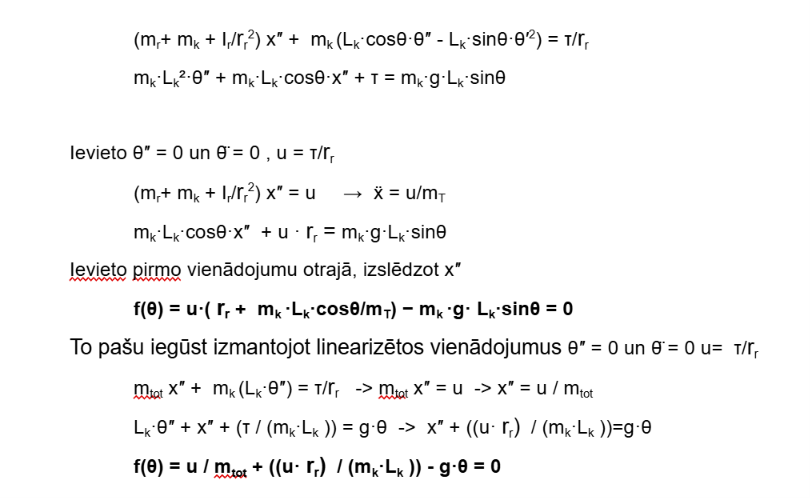

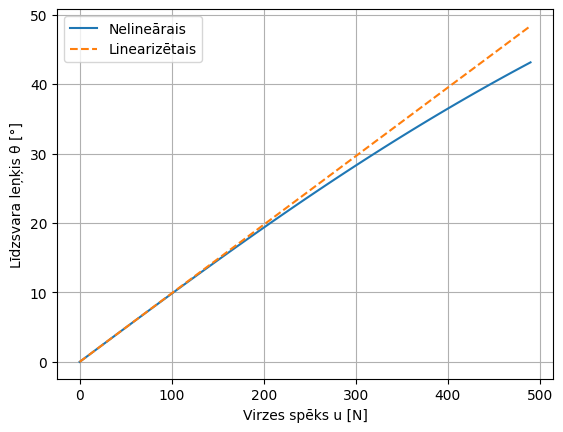

In [13]:
u_vertibas = np.arange(0, 500, 10)
theta_nelin_saraksts = []
theta_lin_saraksts = []

for u in u_vertibas:
    theta_nelin_saraksts.append(fsolve(f, 0)[0])
    theta_lin_saraksts.append(np.rad2deg((u / mT + u * rr / (mk * Lk)) / g))

plt.plot(u_vertibas, theta_nelin_saraksts, label="Nelineārais")
plt.plot(u_vertibas, theta_lin_saraksts, "--", label="Linearizētais")
plt.xlabel("Virzes spēks u [N]")
plt.ylabel("Līdzsvara leņķis θ [°]")
plt.legend()
plt.grid(True)
plt.show()


In [14]:
for u, th_nl, th_lin in zip(u_vertibas, theta_nelin_saraksts, theta_lin_saraksts):
    if th_nl > 0 and abs(th_lin - th_nl) / th_nl * 100 > 5:
        print("Atšķirība > 5 % pie u =", u, "N, θ =", round(th_nl, 1), "°")
        break

Atšķirība > 5 % pie u = 310 N, θ = 29.1 °
